# Cost & latency

Per-refactoring-instance **token usage, USD cost, and wall-clock latency**, by model
and design. Token counts come straight from each result JSON
(`token_usage.total`); USD is a thin layer on top via the editable `PRICING` table in
`utils.cost_latency`; latency is `run_duration_seconds`.

The cost/latency view covers the **D1 and D2** designs. Outputs land under `artifacts/cost_latency/` (CSVs + figures) plus the
LaTeX tables `cost_latency.tex`, `stats_latency.tex`, `stats_tokens.tex`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils import cost_latency as cl, tables

OUT = cl.OUTPUTS
OUT.mkdir(parents=True, exist_ok=True)
DISP = {a: d for d, a in cl.TABLE_MODELS if a}  # alias -> display name

df = cl.add_cost(cl.load_cost_latency())
print(f"instances: {len(df):,}   skipped: {len(df.attrs['skipped'])}   "
      f"latency NaN: {int(df.latency_s.isna().sum())}   cost NaN: {int(df.cost_usd.isna().sum())}")
print("models:", sorted(df.model_alias.dropna().unique()))
df[['model_alias', 'design', 'repetition', 'agent_call_count',
    'latency_s', 'total_tokens', 'cost_usd']].head()

instances: 11,554   skipped: 0   latency NaN: 0   cost NaN: 0
models: ['deepseek-v4-flash', 'gemini35-flash', 'gpt54-nano', 'haiku45']


,model_alias,design,repetition,agent_call_count,latency_s,total_tokens,cost_usd
0,deepseek-v4-flash,D1,1,1,8.319,4376,0.000398
1,deepseek-v4-flash,D1,1,1,13.727,4756,0.000504
2,deepseek-v4-flash,D1,1,1,31.434,14626,0.001455
3,deepseek-v4-flash,D1,1,1,8.299,4275,0.000391
4,deepseek-v4-flash,D1,1,1,14.050,4816,0.000526


## Pricing (USD per 1M tokens)

In [2]:
pd.DataFrame(cl.PRICING).T.rename(columns={
    'in': 'input $/MTok', 'out': 'output $/MTok',
    'cr': 'cache-read $/MTok', 'cw': 'cache-write $/MTok'})

,input $/MTok,output $/MTok
haiku45,1.000,5.000
gpt54-nano,0.200,1.250
gemini35-flash,1.500,9.000
deepseek-v4-flash,0.064,0.251


## Per-model summary (the headline answer)

In [3]:
pm = cl.per_model(df)
pm.to_csv(OUT / 'per_model.csv', index=False)
view = pm.assign(model=pm.model_alias.map(DISP),
                 cost_per_1k=(pm.cost_mean * 1000).round(3))
view[['model', 'n', 'calls_mean', 'latency_med', 'latency_mean', 'in_mean',
      'out_mean', 'tokens_mean', 'cost_per_1k', 'cost_total']].round(2)

,model,n,calls_mean,latency_med,latency_mean,in_mean,out_mean,tokens_mean,cost_per_1k,cost_total
0,DeepSeek V4 Flash,3420,1.24,18.70,26.04,4130.97,2101.86,6232.83,0.79,2.71
1,GPT-5.4-nano,3486,1.22,13.91,30.01,14530.73,4468.76,18999.49,8.49,29.60
2,Claude Haiku 4.5,3486,1.23,15.27,18.92,6787.71,2350.22,9137.92,18.54,64.63
3,Gemini 3.5 Flash,1162,1.21,16.66,20.22,10331.58,1497.60,13355.31,42.71,49.63


In [4]:
pmc = cl.per_model_design(df)
pmc.to_csv(OUT / 'per_model_design.csv', index=False)
pmc.assign(model=pmc.model_alias.map(DISP),
           cost_per_1k=(pmc.cost_mean * 1000).round(3))[
    ['design', 'model', 'n', 'calls_mean', 'latency_med',
     'tokens_mean', 'cost_per_1k']].round(2)

,design,model,n,calls_mean,latency_med,tokens_mean,cost_per_1k
0,D1,DeepSeek V4 Flash,1710,1.00,16.47,6170.02,0.76
1,D1,Gemini 3.5 Flash,581,1.00,17.96,15804.41,48.74
2,D1,GPT-5.4-nano,1743,1.00,15.63,25416.88,11.30
3,D1,Claude Haiku 4.5,1743,1.00,15.37,8661.54,17.55
4,D2,DeepSeek V4 Flash,1710,1.47,23.75,6295.65,0.82
5,D2,Gemini 3.5 Flash,581,1.43,9.73,10906.22,36.68
6,D2,GPT-5.4-nano,1743,1.44,11.19,12582.10,5.68
7,D2,Claude Haiku 4.5,1743,1.46,15.00,9614.30,19.53


## Cost vs. latency scatter

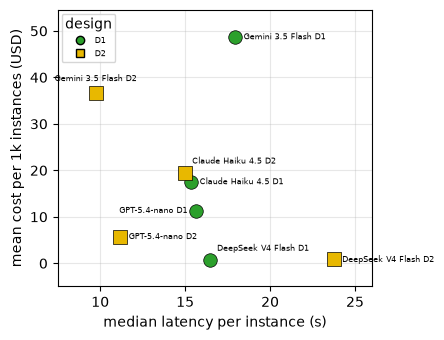

In [5]:
# marker = design, colour = model, per-point '<model> <design>' labels.
LABELPOS = {
    ('gemini35-flash', 'D1'): 'right', ('gemini35-flash', 'D2'): 'up',
    ('haiku45', 'D1'): 'right',
    ('haiku45', 'D2'): 'upright', ('gpt54-nano', 'D1'): 'left', ('gpt54-nano', 'D2'): 'right',
    ('deepseek-v4-flash', 'D1'): 'upright',
    ('deepseek-v4-flash', 'D2'): 'right', }
fig = cl.plot_combined_scatter(
    pmc, x='latency_med', y='cost_mean', yscale=1000,
    xlabel='median latency per instance (s)',
    ylabel='mean cost per 1k instances (USD)', label_dirs=LABELPOS)
fig.savefig(OUT / 'cost_vs_latency.png', dpi=300, bbox_inches='tight')
plt.show()

## Distributions: latency spread & token breakdown

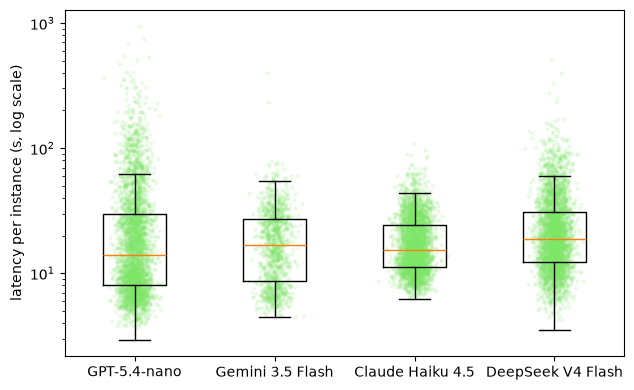

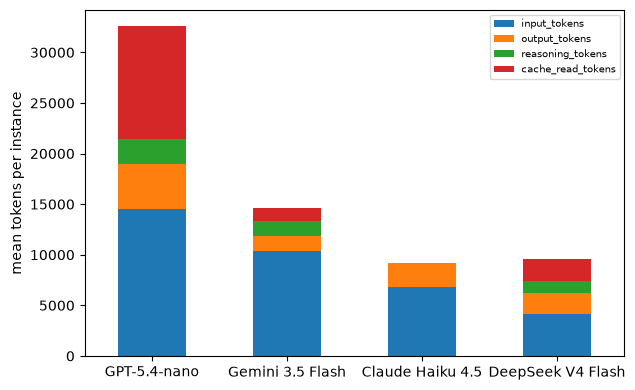

In [6]:
rng = np.random.default_rng(42)
order = [a for _, a in cl.TABLE_MODELS if a and a in df.model_alias.values]

# Latency distribution: boxplot + jittered raw points, log-y (long tail).
fig, ax = plt.subplots(figsize=(6.5, 4))
data = [df.loc[df.model_alias == a, 'latency_s'].dropna().values for a in order]
ax.boxplot(data, tick_labels=[DISP[a] for a in order], showfliers=False, zorder=3)
for i, v in enumerate(data, start=1):
    ax.scatter(rng.normal(i, 0.06, size=len(v)), v, s=4, alpha=0.12,
               color="#7ee667", zorder=1)
ax.set_yscale('log')
ax.set_ylabel('latency per instance (s, log scale)')
plt.tight_layout()
plt.savefig(OUT / 'latency_distribution.png', dpi=300)
plt.show()

# Token breakdown: what drives cost (input vs output vs cache), mean/instance.
fig, ax = plt.subplots(figsize=(6.5, 4))
tok = (df.groupby('model_alias', observed=True)[
          ['input_tokens', 'output_tokens', 'reasoning_tokens',
           'cache_read_tokens']].mean().reindex(order))
tok.index = [DISP[a] for a in tok.index]
tok.plot.bar(stacked=True, ax=ax)
ax.set_ylabel('mean tokens per instance')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=0)
ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(OUT / 'token_breakdown.png', dpi=300)
plt.show()

## Decomposition & validation-loop overhead

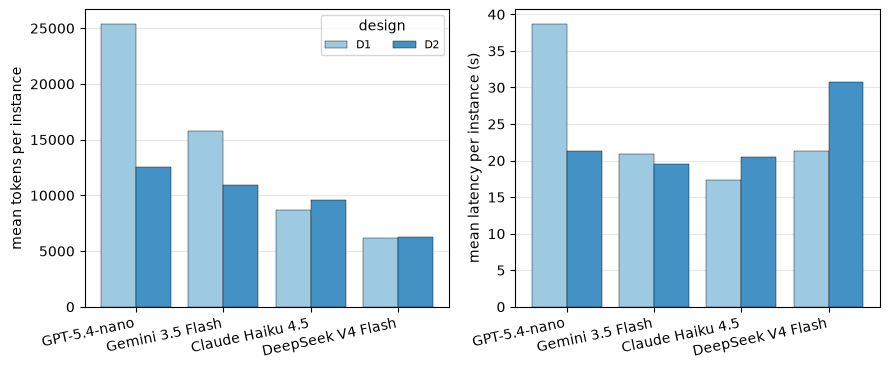

,design,n,calls_mean,tokens_mean,latency_med,latency_mean,calls_x,tokens_x,latency_x
0,D1,5777,1.00,13697.73,16.10,25.35,1.00,1.00,1.00
1,D2,5777,1.45,9657.33,16.53,23.66,1.45,0.71,0.93


In [7]:
ob = cl.overhead_by_design(df)
ob.to_csv(OUT / 'overhead.csv', index=False)
fig = cl.plot_overhead(df)
fig.savefig(OUT / 'overhead.png', dpi=300, bbox_inches='tight')
plt.show()
ob[['design', 'n', 'calls_mean', 'tokens_mean', 'latency_med',
    'latency_mean', 'calls_x', 'tokens_x', 'latency_x']].round(2)

## Quality vs. cost trade-off (faceted by design)

In [8]:
tf = cl.tradeoff_frame()  # F1 (rep1, n15 GT) joined to cost/latency
tf.to_csv(OUT / 'tradeoff.csv', index=False)
tf.assign(model=tf.model_alias.map(DISP))[
    ['design', 'model', 'n', 'F1', 'calls_mean', 'latency_med',
     'cost_mean', 'tokens_mean']].round(3)

,design,model,n,F1,calls_mean,latency_med,cost_mean,tokens_mean
0,D1,DeepSeek V4 Flash,570,0.883,1.000,16.469,0.001,6170.016
1,D1,Gemini 3.5 Flash,570,0.869,1.000,17.957,0.049,15804.406
2,D1,GPT-5.4-nano,570,0.814,1.000,15.276,0.012,28605.862
3,D1,Claude Haiku 4.5,570,0.888,1.000,15.171,0.017,8504.941
4,D2,DeepSeek V4 Flash,570,0.880,1.475,23.754,0.001,6295.653
5,D2,Gemini 3.5 Flash,570,0.865,1.429,9.734,0.037,10906.215
6,D2,GPT-5.4-nano,570,0.872,1.446,11.221,0.006,14754.473
7,D2,Claude Haiku 4.5,570,0.885,1.451,15.118,0.020,9646.745


saved: ['f1_vs_cost/d1.png', 'f1_vs_cost/d2.png']


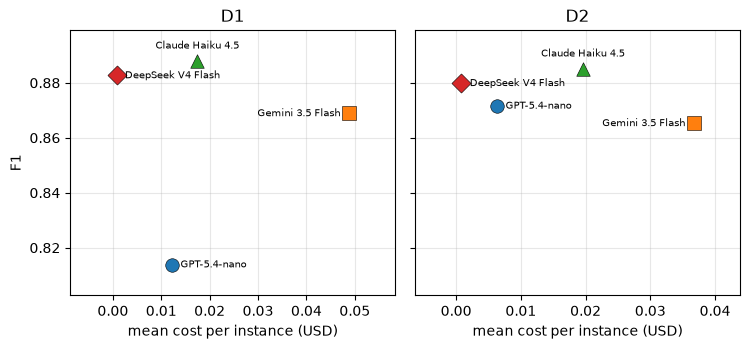

In [9]:
F1_LABELS = {
    'D1': {'gpt54-nano': 'right', 'haiku45': 'up', 'gemini35-flash': 'left'},
    'D2': {'gpt54-nano': 'right', 'haiku45': 'up', 'gemini35-flash': 'left'},
}
# Combined panels shown for inspection; the LaTeX deliverable is the per-design
# subfigure dir f1_vs_cost/{d1,d2}.png (shared y-axis, F1 only on d1).
cl.plot_tradeoff(tf, x='cost_mean', xlabel='mean cost per instance (USD)',
                 label_dirs=F1_LABELS)
saved = cl.save_tradeoff_per_design(tf, OUT, 'f1_vs_cost', x='cost_mean',
                                    xlabel='mean cost per instance (USD)',
                                    label_dirs=F1_LABELS)
print('saved:', [str(p.relative_to(OUT)) for p in saved])
plt.show()

### Combined f1_vs_cost

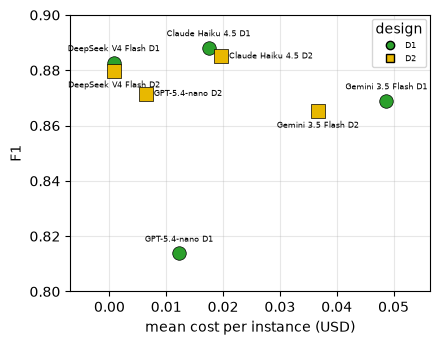

In [10]:
F1C_LABELS = {
    ('gpt54-nano', 'D1'): 'up', ('gpt54-nano', 'D2'): 'right', ('haiku45', 'D1'): 'up', ('haiku45', 'D2'): 'right', ('gemini35-flash', 'D1'): 'up', ('gemini35-flash', 'D2'): 'down', ('deepseek-v4-flash', 'D1'): 'up', ('deepseek-v4-flash', 'D2'): 'down', }
fig = cl.plot_combined_scatter(
    tf, x='cost_mean', y='F1', xlabel='mean cost per instance (USD)', ylabel='F1',
    label_dirs=F1C_LABELS)
fig.axes[0].set_ylim(.8, .9)
fig.savefig(OUT / 'f1_vs_cost.png', dpi=300, bbox_inches='tight')
plt.show()

### Combined f1_vs_latency

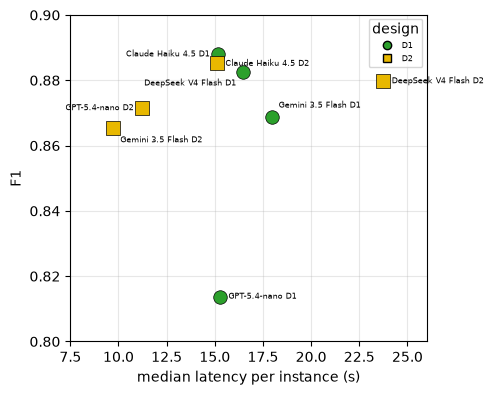

In [11]:
F1L_LABELS = {
    ('gpt54-nano', 'D1'): 'right', ('gpt54-nano', 'D2'): 'left', ('haiku45', 'D1'): 'left', ('haiku45', 'D2'): 'right', ('gemini35-flash', 'D1'): 'upright', ('gemini35-flash', 'D2'): 'downright', ('deepseek-v4-flash', 'D1'): 'downleft', ('deepseek-v4-flash', 'D2'): 'right', }
fig = cl.plot_combined_scatter(
    tf, x='latency_med', y='F1', xlabel='median latency per instance (s)', ylabel='F1',
    label_dirs=F1L_LABELS, figsize=(5, 4))
fig.axes[0].set_ylim(.8, .9)
fig.savefig(OUT / 'f1_vs_latency.png', dpi=300, bbox_inches='tight')
plt.show()

## LaTeX tables

`cost_latency.tex` (per-model cost/latency), plus the design-effect
significance tables `stats_latency.tex` / `stats_tokens.tex` (Cliff's δ + paired
Wilcoxon, Holm-corrected, the D1-D2 comparison).

In [12]:
cost_tex = tables.cost_latency_table()   # -> artifacts/cost_latency/cost_latency.tex
lat_tex = tables.stats_latency_table()    # -> artifacts/stats_latency.tex
tok_tex = tables.stats_tokens_table()     # -> artifacts/stats_tokens.tex
# print(cost_tex)